In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("../data/raw/cbc_raw.csv")
df.head()

,GENDER,WBC,NE#,LY#,MO#,EO#,BA#,RBC,HGB,HCT,...,PLT,MPV,PCT,PDW,SD,SDTSD,TSD,FERRITTE,FOLATE,B12
0,1,106.32,93.10,6.01,1.72,1.67,3.82,4.27,12.40,38.10,...,240.00,8.70,0.21,8.50,85.00,409.40,20.762091,195.40,5.91,1879.0
1,1,89.31,7.67,78.98,0.54,0.04,2.09,4.97,11.46,36.44,...,75.99,12.29,0.09,22.87,78.00,369.40,21.115322,373.50,7.25,1121.0
2,1,85.73,75.17,4.55,4.34,0.20,1.46,4.99,14.68,46.96,...,160.90,8.89,0.14,19.72,111.00,402.00,27.611940,51.10,7.01,1612.0
3,1,73.09,3.42,66.45,0.76,0.09,2.37,4.37,13.24,39.30,...,116.70,7.06,0.08,20.75,69.00,383.00,18.015666,89.33,14.61,433.5
4,1,60.87,3.23,54.05,1.67,0.30,1.61,3.62,10.89,33.21,...,125.50,10.22,0.13,22.12,74.27,356.37,20.840699,94.38,5.81,363.5


In [3]:
# Drop redundant features, features out of project scope, machine-specific variance metrics,
# and noisy platelet indices to prevent overfitting in tree-based models.

columns_to_drop = ["BA#", "MPV", "PCT", "PDW", "SD", "SDTSD", "TSD", "FOLATE", "B12"]
df = df.drop(columns=columns_to_drop, errors="ignore")

In [4]:
# Standardize feature names: remove special characters ('#') for
# XGBoost/LightGBM compatibility (JSON/Booster parsing) and fix a typo.

df = df.rename(columns={
    'NE#': 'NE',
    'LY#': 'LY',
    'EO#': 'EO',
    'MO#': 'MO',
    'FERRITTE': 'FERRITIN'
})

In [5]:
# Feature Engineering: Mentzer Index (MCV / RBC ratio)
# Domain Rationale: Directly injects clinical diagnostic logic into the feature space to assist
# tree splits in distinguishing microcytic anemias:
#   - Mentzer Index < 13  --> High probability of Thalassemia Trait
#   - Mentzer Index > 13  --> High probability of Iron Deficiency Anemia (IDA)
# Implementation: Vectorized array operations (O(N)) preferred over pandas .apply() (O(N) with Python overhead)
# to optimize execution time across large matrices.

# Vectorized Mentzer Index calculation with safety check against division by zero
df["MENTZER_INDEX"] = np.where(
    df["RBC"] > 0,
    (df["MCV"] / df["RBC"]).round(2),
    np.nan
)

# Previously used function/method for index calculation
# df["MENTZER_INDEX"] = df.apply(lambda row: round(row["MCV"] / row["RBC"], 2), axis=1)

In [6]:
# Initial data audit: The dataset arrived unlabeled and undocumented.
# To bootstrap a supervised learning workflow, we deploy a rule-based clinical
# logic engine to reverse-engineer 12 distinct binary pathology targets.

df.info()
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   GENDER         30000 non-null  int64  
 1   WBC            30000 non-null  float64
 2   NE             30000 non-null  float64
 3   LY             30000 non-null  float64
 4   MO             30000 non-null  float64
 5   EO             30000 non-null  float64
 6   RBC            30000 non-null  float64
 7   HGB            30000 non-null  float64
 8   HCT            30000 non-null  float64
 9   MCV            30000 non-null  float64
 10  MCH            30000 non-null  float64
 11  MCHC           30000 non-null  float64
 12  RDW            30000 non-null  float64
 13  PLT            30000 non-null  float64
 14  FERRITIN       30000 non-null  float64
 15  MENTZER_INDEX  30000 non-null  float64
dtypes: float64(15), int64(1)
memory usage: 3.7 MB


,count,mean,std,min,25%,50%,75%,max
GENDER,30000.0,0.393267,0.488483,0.00,0.0000,0.000,1.0000,1.00
WBC,30000.0,64.741016,76.447472,0.57,7.2995,12.445,121.0650,246.70
NE,30000.0,50.717203,61.355523,0.03,4.2800,9.125,96.3450,197.20
LY,30000.0,23.097595,27.946269,0.11,2.0600,3.520,44.0800,89.60
MO,30000.0,4.832011,5.741358,0.00,0.5100,0.930,9.1025,18.51
EO,30000.0,2.393830,2.976138,0.00,0.1100,0.380,4.6300,9.41
RBC,30000.0,4.450508,1.447098,0.87,3.7775,4.620,5.2800,7.50
HGB,30000.0,12.786489,4.192183,2.99,10.5000,12.820,15.1000,22.45
HCT,30000.0,38.054165,12.852927,7.21,31.8600,38.800,44.8500,67.40
MCV,30000.0,85.447920,16.300780,49.93,76.6175,84.800,92.4000,125.30


In [7]:
# Demographic Inference: Decode the unmapped binary 'GENDER' column using
# physiological baselines (testosterone-driven differences in HGB, RBC, and HCT).
# The group with higher erythroid mass is programmatically mapped to Male.

gender_medians = df.groupby('GENDER')[['HGB', 'RBC', 'HCT']].median()
display(gender_medians)

# Programmatically map based on higher mean erythoid mass
male_label = gender_medians['HGB'].idxmax()
female_label = gender_medians['HGB'].idxmin()

gender_map = {female_label: 'Female', male_label: 'Male'}
df['GENDER_LABEL'] = df['GENDER'].map(gender_map)

print(f"Inferred Mapping: Class {male_label} -> Male | Class {female_label} -> Female")

,HGB,RBC,HCT
GENDER,,,
0,12.53,4.571,38.145
1,13.56,4.735,40.500


Inferred Mapping: Class 1 -> Male | Class 0 -> Female


In [8]:
# Clinical Outlier Audit: In standard tabular ML, statistical extremes are
# routinely pruned. However, in healthcare data, extreme IQR values often reflect
# acute medical crises (e.g., severe hyperferritinemia) rather than noise or corruption.
# We audit rather than drop to preserve high-risk pathological signatures.

def audit_clinical_outliers(df, threshold=1.5):
    """
    Audits IQR-based statistical extremes across continuous clinical features.
    Used strictly for diagnostic reporting to protect vital edge-case data.
    """
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    numeric_cols = [c for c in numeric_cols if c != 'GENDER']

    outlier_report = []
    for col in numeric_cols:
        Q1, Q3 = df[col].quantile([0.25, 0.75])
        iqr = Q3 - Q1
        lower = Q1 - (threshold * iqr)
        upper = Q3 + (threshold * iqr)

        mask = (df[col] < lower) | (df[col] > upper)
        count = mask.sum()
        pct = (count / len(df)) * 100

        outlier_report.append({
            'Feature': col,
            'Outlier Count': count,
            'Outlier Pct (%)': round(pct, 2)
        })

    return (
        pd.DataFrame(outlier_report)
        .sort_values(by='Outlier Pct (%)', ascending=False)
        .reset_index(drop=True)
    )

# Execute the clinical outlier audit
outlier_df = audit_clinical_outliers(df)
display(outlier_df)

,Feature,Outlier Count,Outlier Pct (%)
0,MENTZER_INDEX,3851,12.84
1,MCV,2405,8.02
2,HCT,2052,6.84
3,RBC,1431,4.77
4,HGB,770,2.57
5,LY,0,0.00
6,WBC,0,0.00
7,MO,0,0.00
8,EO,0,0.00
9,NE,0,0.00


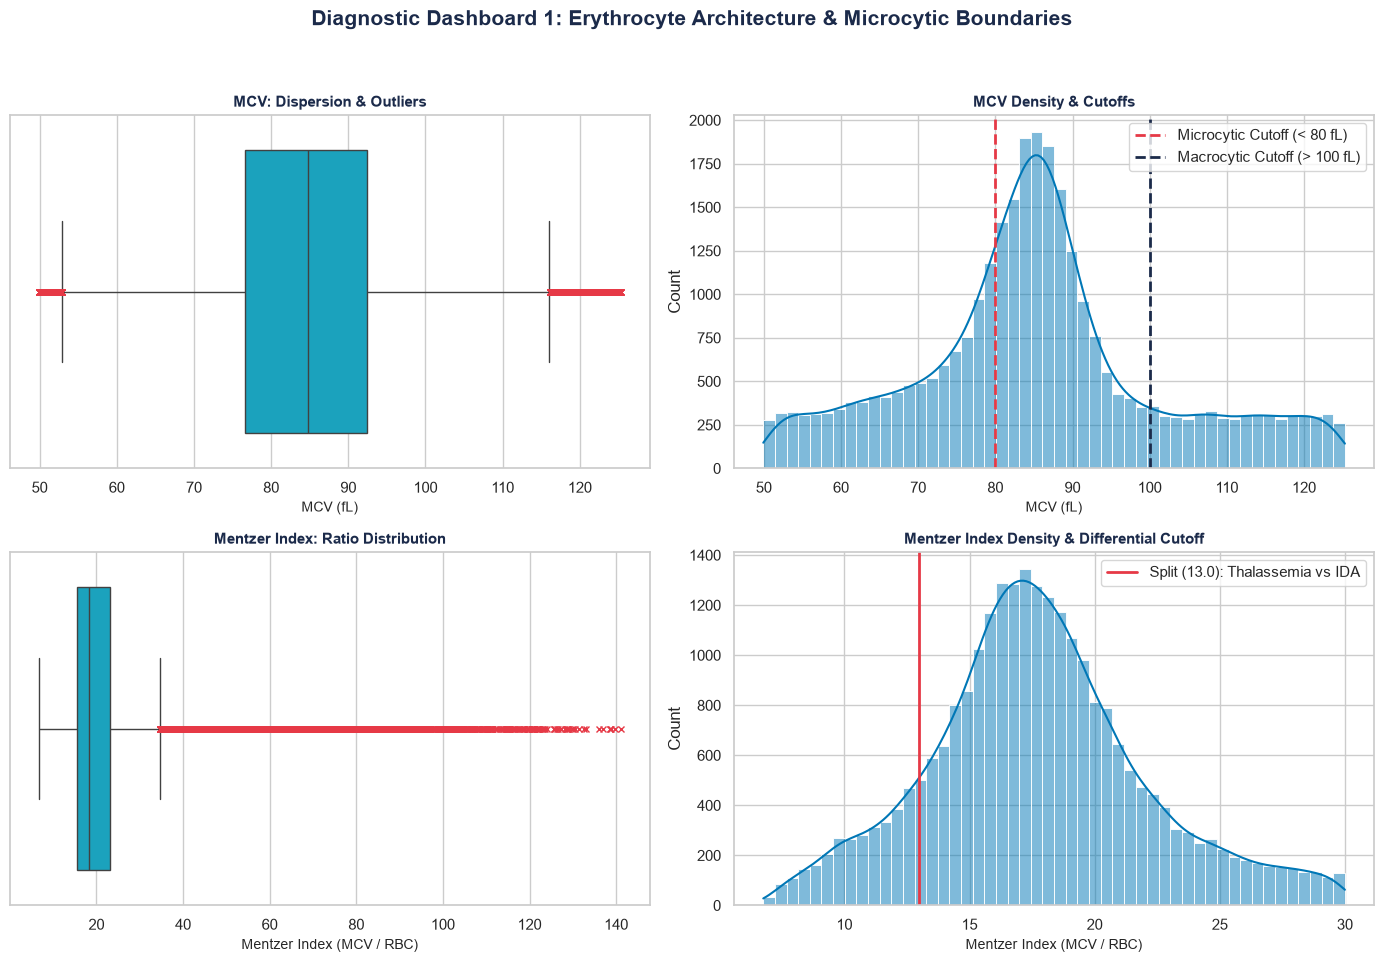

In [9]:
# ==============================================================================
# DASHBOARD 1: Erythrocyte Architecture & Microcytic Boundaries
# Visualizing distributions and clinical thresholds for MCV and Mentzer Index.
# ==============================================================================

PALETTE = {
    "primary": "#0077B6",      # Deep Clinical Blue
    "secondary": "#00B4D8",    # Soft Blue
    "dark_navy": "#1B2A4A",    # Dark Accent
    "alert_red": "#E63946"     # Threshold Marker
}

sns.set_theme(style="whitegrid", font="sans-serif")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Diagnostic Dashboard 1: Erythrocyte Architecture & Microcytic Boundaries",
    fontsize=15, fontweight='bold', color=PALETTE["dark_navy"], y=0.96
)

# 1. MCV Boxplot
sns.boxplot(
    x=df['MCV'], ax=axes[0, 0], color=PALETTE["secondary"],
    flierprops={"marker": "x", "markerfacecolor": PALETTE["alert_red"], "markersize": 5, "markeredgecolor": PALETTE["alert_red"]}
)
axes[0, 0].set_title("MCV: Dispersion & Outliers", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[0, 0].set_xlabel("MCV (fL)", fontsize=10)

# 2. MCV Density & Clinical Cutoffs
sns.histplot(df['MCV'], bins=50, kde=True, ax=axes[0, 1], color=PALETTE["primary"])
axes[0, 1].axvline(80.0, color=PALETTE["alert_red"], linestyle='--', linewidth=2, label='Microcytic Cutoff (< 80 fL)')
axes[0, 1].axvline(100.0, color=PALETTE["dark_navy"], linestyle='--', linewidth=2, label='Macrocytic Cutoff (> 100 fL)')
axes[0, 1].set_title("MCV Density & Cutoffs", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[0, 1].set_xlabel("MCV (fL)", fontsize=10)
axes[0, 1].legend(loc='upper right', frameon=True)

# 3. Mentzer Index Boxplot
sns.boxplot(
    x=df['MENTZER_INDEX'], ax=axes[1, 0], color=PALETTE["secondary"],
    flierprops={"marker": "x", "markerfacecolor": PALETTE["alert_red"], "markersize": 5, "markeredgecolor": PALETTE["alert_red"]}
)
axes[1, 0].set_title("Mentzer Index: Ratio Distribution", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[1, 0].set_xlabel("Mentzer Index (MCV / RBC)", fontsize=10)

# 4. Mentzer Index Density & Split
sns.histplot(df[df['MENTZER_INDEX'] <= 30]['MENTZER_INDEX'], bins=50, kde=True, ax=axes[1, 1], color=PALETTE["primary"])
axes[1, 1].axvline(13.0, color=PALETTE["alert_red"], linestyle='-', linewidth=2, label='Split (13.0): Thalassemia vs IDA')
axes[1, 1].set_title("Mentzer Index Density & Differential Cutoff", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[1, 1].set_xlabel("Mentzer Index (MCV / RBC)", fontsize=10)
axes[1, 1].legend(loc='upper right', frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

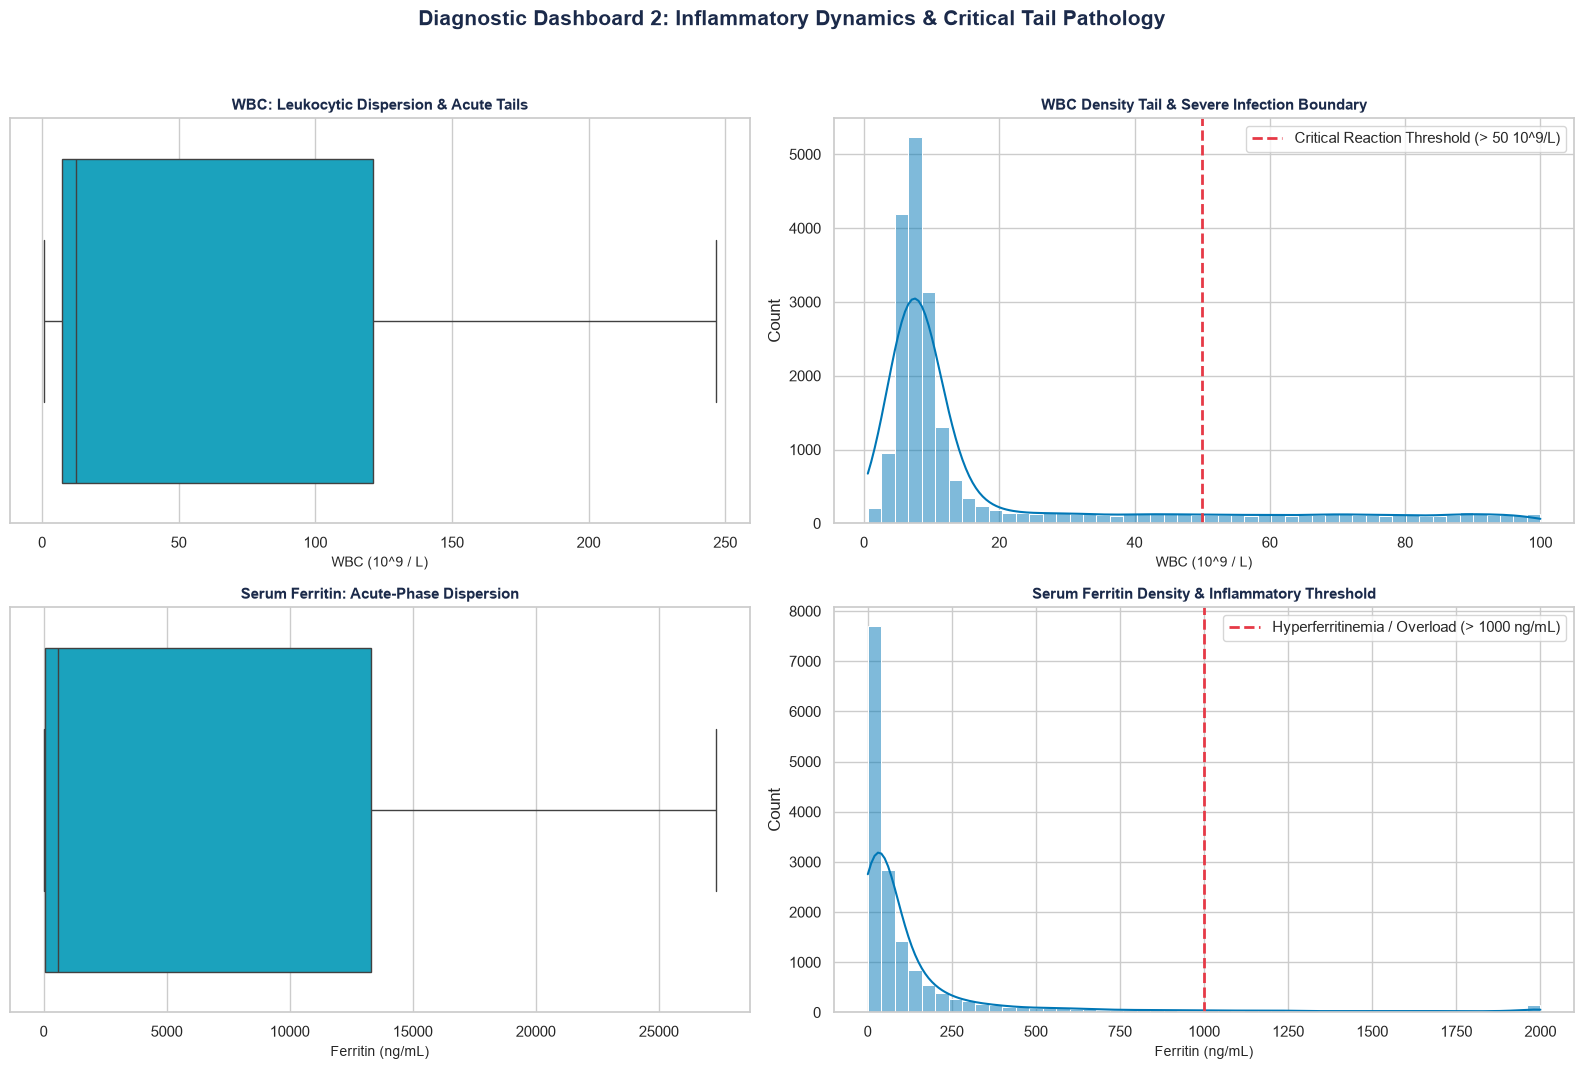

In [10]:
# ==============================================================================
# DASHBOARD 2: Inflammatory Dynamics & Critical Tail Pathology
# Isolating skewed, high-risk outliers representing acute medical crises.
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    "Diagnostic Dashboard 2: Inflammatory Dynamics & Critical Tail Pathology",
    fontsize=15, fontweight='bold', color=PALETTE["dark_navy"], y=0.97
)

# 1. WBC Boxplot
sns.boxplot(
    x=df['WBC'], ax=axes[0, 0], color=PALETTE["secondary"],
    flierprops={"marker": "x", "markerfacecolor": PALETTE["alert_red"], "markersize": 4, "markeredgecolor": PALETTE["alert_red"]}
)
axes[0, 0].set_title("WBC: Leukocytic Dispersion & Acute Tails", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[0, 0].set_xlabel("WBC (10^9 / L)", fontsize=10)

# 2. WBC Density Tail & Critical Boundary
sns.histplot(df[df['WBC'] <= 100]['WBC'], bins=50, kde=True, ax=axes[0, 1], color=PALETTE["primary"])
axes[0, 1].axvline(50.0, color=PALETTE["alert_red"], linestyle='--', linewidth=2, label='Critical Reaction Threshold (> 50 10^9/L)')
axes[0, 1].set_title("WBC Density Tail & Severe Infection Boundary", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[0, 1].set_xlabel("WBC (10^9 / L)", fontsize=10)
axes[0, 1].legend(loc='upper right', frameon=True)

# 3. Serum Ferritin Boxplot
sns.boxplot(
    x=df['FERRITIN'].dropna(), ax=axes[1, 0], color=PALETTE["secondary"],
    flierprops={"marker": "x", "markerfacecolor": PALETTE["alert_red"], "markersize": 5, "markeredgecolor": PALETTE["alert_red"]}
)
axes[1, 0].set_title("Serum Ferritin: Acute-Phase Dispersion", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[1, 0].set_xlabel("Ferritin (ng/mL)", fontsize=10)

# 4. Ferritin Density Tail & Overload Boundary
sns.histplot(df[df['FERRITIN'] <= 2000]['FERRITIN'].dropna(), bins=50, kde=True, ax=axes[1, 1], color=PALETTE["primary"])
axes[1, 1].axvline(1000.0, color=PALETTE["alert_red"], linestyle='--', linewidth=2, label='Hyperferritinemia / Overload (> 1000 ng/mL)')
axes[1, 1].set_title("Serum Ferritin Density & Inflammatory Threshold", fontsize=11, fontweight='bold', color=PALETTE["dark_navy"])
axes[1, 1].set_xlabel("Ferritin (ng/mL)", fontsize=10)
axes[1, 1].legend(loc='upper right', frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [11]:
def check_result_thresholds(df):
    # Instead of using arbitrary mathematical outliers, we audit actual medical crises boundaries.
    thresholds = {
        'WBC': 50.0,       # Critical Leukocytosis / Suspected Leukemia / Hyperinflammation / Severe Sepsis
        'HGB': 20.0,       # Polycythemia Vera / Critical Hemoconcentration (Very thick blood)
        'RBC': 6.5,        # Extreme Erythrocytosis (Massive overproduction of red blood cells)
        'PLT': 1000.0,     # Extreme Essential Thrombocythemia (Stroke Risk)
        'MCV': 120.0,      # Extreme Macrocytosis / Pernicious Anemia
        'FERRITIN': 1000.0, # Severe Iron Overload / Hemochromatosis / Acute Phase Reactant
        'MENTZER_INDEX': 25.0  # Extreme Microcytic Anemia Deviation (Severe Iron Deficiency Signature)
    }

    threshold_report = []
    for col, val in thresholds.items():
        if col in df.columns:
            count = len(df[df[col] > val])
            percentage = (count / len(df)) * 100
            threshold_report.append({
                'Parameter': col,
                'Threshold': val,
                'Count Above': count,
                'Percentage': f"{percentage:.2f}%"
            })

    return pd.DataFrame(threshold_report)

print(check_result_thresholds(df))

# ================================================================================
# Why Standard Outlier Pruning Fails Here
# ================================================================================
# The data above shows that extreme values represent real, life-threatening pathologies.
# Dropping them as 'noise' would erase the exact target signal we need to learn.
#
# Since we are deploying tree-based models, we can leverage their ability to map
# non-linear step-functions and heavy tails. The models will easily segment these
# diagnostic cliffs, so we are keeping 100% of the rows for training.
# ================================================================================

       Parameter  Threshold  Count Above Percentage
0            WBC       50.0        11710     39.03%
1            HGB       20.0         1861      6.20%
2            RBC        6.5         2364      7.88%
3            PLT     1000.0         6391     21.30%
4            MCV      120.0         1038      3.46%
5       FERRITIN     1000.0        14473     48.24%
6  MENTZER_INDEX       25.0         6450     21.50%


In [12]:
# ==============================================================================
# KNOWLEDGE-BASED CLINICAL LABELLING ENGINE (Multi-Label Target Generation)
# Derives 12 binary pathology targets from hematological guidelines,
# allowing for co-occurring medical conditions. (Idempotent implementation)
# ==============================================================================

def master_diagnostic_engine(row):
    res = {
        'LEUKEMIA_SUSPECT': 0, 'BACTERIAL_INF': 0, 'VIRAL_INF': 0,
        'MONOCYTOSIS': 0, 'EOSINOPHILIA': 0, 'IRON_DEFICIENCY_ANEMIA': 0,
        'THALASSEMIA_TRAIT': 0, 'CHRONIC_DISEASE_ANEMIA': 0, 'THROMBOCYTOSIS': 0,
        'THROMBOCYTOPENIA': 0
    }

    # 1. Leukocyte Pathways (WBC & Differentials)
    if row['WBC'] > 50: res['LEUKEMIA_SUSPECT'] = 1
    if row['WBC'] > 11:
        if row['NE'] > row['LY'] and row['NE'] > 8: res['BACTERIAL_INF'] = 1
        elif row['LY'] > row['NE'] and row['LY'] > 4.8: res['VIRAL_INF'] = 1
    if row['EO'] > 0.5: res['EOSINOPHILIA'] = 1
    if row['MO'] > 0.9: res['MONOCYTOSIS'] = 1

    # 2. Erythrocyte & Anemia Pathways (Gender-Stratified HGB)
    is_anemic = (row['GENDER'] == 1 and row['HGB'] < 13.5) or (row['GENDER'] == 0 and row['HGB'] < 12.0)

    if is_anemic and row['MCV'] < 80:
        # Differentiating microcytic tracks using Mentzer Index & RDW
        rdw = row.get('RDW', 14.0)
        if row['MENTZER_INDEX'] < 13 or (not pd.isna(rdw) and rdw < 14.5):
            res['THALASSEMIA_TRAIT'] = 1
        else:
            if not pd.isna(row['FERRITIN']):
                if row['FERRITIN'] < 30:
                    res['IRON_DEFICIENCY_ANEMIA'] = 1
                else:
                    res['CHRONIC_DISEASE_ANEMIA'] = 1

    # 3. Thrombocyte Pathways (Platelets)
    if row['PLT'] > 450: res['THROMBOCYTOSIS'] = 1
    elif row['PLT'] < 150: res['THROMBOCYTOPENIA'] = 1

    return pd.Series(res)

# List of target columns to manage idempotency
diagnostic_labels = [
    'LEUKEMIA_SUSPECT', 'BACTERIAL_INF', 'VIRAL_INF',
    'MONOCYTOSIS', 'EOSINOPHILIA', 'IRON_DEFICIENCY_ANEMIA', 'THALASSEMIA_TRAIT',
    'CHRONIC_DISEASE_ANEMIA', 'THROMBOCYTOSIS', 'THROMBOCYTOPENIA', 'HEALTHY_CONTROL'
]

# Drop existing target columns if re-running the cell to prevent duplication bugs
df = df.drop(columns=[col for col in diagnostic_labels if col in df.columns], errors='ignore')

# Execute engine, derive healthy baseline, and concatenate target matrix cleanly
target_df = df.apply(master_diagnostic_engine, axis=1)
target_df['HEALTHY_CONTROL'] = (target_df.sum(axis=1) == 0).astype(int)
df = pd.concat([df, target_df], axis=1)

print(f"Target matrix successfully engineered: {target_df.shape[1]} target classes generated.")

Target matrix successfully engineered: 11 target classes generated.


In [13]:
df.info()
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   GENDER                  30000 non-null  int64  
 1   WBC                     30000 non-null  float64
 2   NE                      30000 non-null  float64
 3   LY                      30000 non-null  float64
 4   MO                      30000 non-null  float64
 5   EO                      30000 non-null  float64
 6   RBC                     30000 non-null  float64
 7   HGB                     30000 non-null  float64
 8   HCT                     30000 non-null  float64
 9   MCV                     30000 non-null  float64
 10  MCH                     30000 non-null  float64
 11  MCHC                    30000 non-null  float64
 12  RDW                     30000 non-null  float64
 13  PLT                     30000 non-null  float64
 14  FERRITIN                30000 non-null  float64
 

,count,mean,std,min,25%,50%,75%,max
GENDER,30000.0,0.393267,0.488483,0.00,0.0000,0.000,1.0000,1.00
WBC,30000.0,64.741016,76.447472,0.57,7.2995,12.445,121.0650,246.70
NE,30000.0,50.717203,61.355523,0.03,4.2800,9.125,96.3450,197.20
LY,30000.0,23.097595,27.946269,0.11,2.0600,3.520,44.0800,89.60
MO,30000.0,4.832011,5.741358,0.00,0.5100,0.930,9.1025,18.51
EO,30000.0,2.393830,2.976138,0.00,0.1100,0.380,4.6300,9.41
RBC,30000.0,4.450508,1.447098,0.87,3.7775,4.620,5.2800,7.50
HGB,30000.0,12.786489,4.192183,2.99,10.5000,12.820,15.1000,22.45
HCT,30000.0,38.054165,12.852927,7.21,31.8600,38.800,44.8500,67.40
MCV,30000.0,85.447920,16.300780,49.93,76.6175,84.800,92.4000,125.30


In [14]:
# Data Quality Gate: Hematological 'Rule of Three' Validation
# Biological baseline: HCT (%) should closely approximate 3 * HGB (g/dL).
# Deviations > 6% signal severe pre-analytical errors (e.g., sample dilution,
# instrument faults). We prune these anomalies to ensure training data integrity.

is_invalid = (df['HCT'] - (df['HGB'] * 3)).abs() > 6

anomaly_count = is_invalid.sum()
retention_pct = ((len(df) - anomaly_count) / len(df)) * 100

df = df[~is_invalid].copy()

print(f"Rule of Three Quality Gate:")
print(f" - Flagged & Purged Anomalies: {anomaly_count:,}")
print(f" - Clean Dataset Retained: {len(df):,} rows ({retention_pct:.2f}%)")

Rule of Three Quality Gate:
 - Flagged & Purged Anomalies: 11,919
 - Clean Dataset Retained: 18,081 rows (60.27%)


In [15]:
# Create a list of all engineered diagnostic columns (including Healthy Control)
diagnostic_labels = [
    'LEUKEMIA_SUSPECT', 'BACTERIAL_INF', 'VIRAL_INF',
    'MONOCYTOSIS', 'EOSINOPHILIA', 'IRON_DEFICIENCY_ANEMIA', 'THALASSEMIA_TRAIT',
    'CHRONIC_DISEASE_ANEMIA', 'THROMBOCYTOSIS', 'THROMBOCYTOPENIA', 'HEALTHY_CONTROL'
]

# Calculate absolute frequency across all target classes
case_counts = df[diagnostic_labels].sum().sort_values(ascending=False)

# Calculate multi-label co-occurrence statistics
total_samples = len(df)
healthy_count = int(df['HEALTHY_CONTROL'].sum())
diseased_samples = (df[diagnostic_labels[:-1]].sum(axis=1) > 0).sum()
co_occurring_samples = (df[diagnostic_labels[:-1]].sum(axis=1) > 1).sum()

print("--- CLINICAL TARGET FREQUENCY SUMMARY ---")
print(case_counts)
print("\n--- CO-OCCURRENCE & UTILIZATION AUDIT ---")
print(f"Total Working Samples : {total_samples:,}")
print(f"Healthy Control Rows  : {healthy_count:,} ({healthy_count/total_samples*100:.2f}%)")
print(f"Pathological Rows     : {diseased_samples:,} ({diseased_samples/total_samples*100:.2f}%)")
print(f"Multi-Label Overlaps  : {co_occurring_samples:,} ({co_occurring_samples/total_samples*100:.2f}%)")

--- CLINICAL TARGET FREQUENCY SUMMARY ---
HEALTHY_CONTROL           9677
MONOCYTOSIS               3895
BACTERIAL_INF             3425
EOSINOPHILIA              3109
THROMBOCYTOSIS            2608
LEUKEMIA_SUSPECT          2330
THROMBOCYTOPENIA          1536
THALASSEMIA_TRAIT         1287
IRON_DEFICIENCY_ANEMIA    1128
CHRONIC_DISEASE_ANEMIA     688
VIRAL_INF                  670
dtype: int64

--- CO-OCCURRENCE & UTILIZATION AUDIT ---
Total Working Samples : 18,081
Healthy Control Rows  : 9,677 (53.52%)
Pathological Rows     : 8,404 (46.48%)
Multi-Label Overlaps  : 4,176 (23.10%)


C:\Users\User\AppData\Local\Temp\ipykernel_28424\3381267486.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')


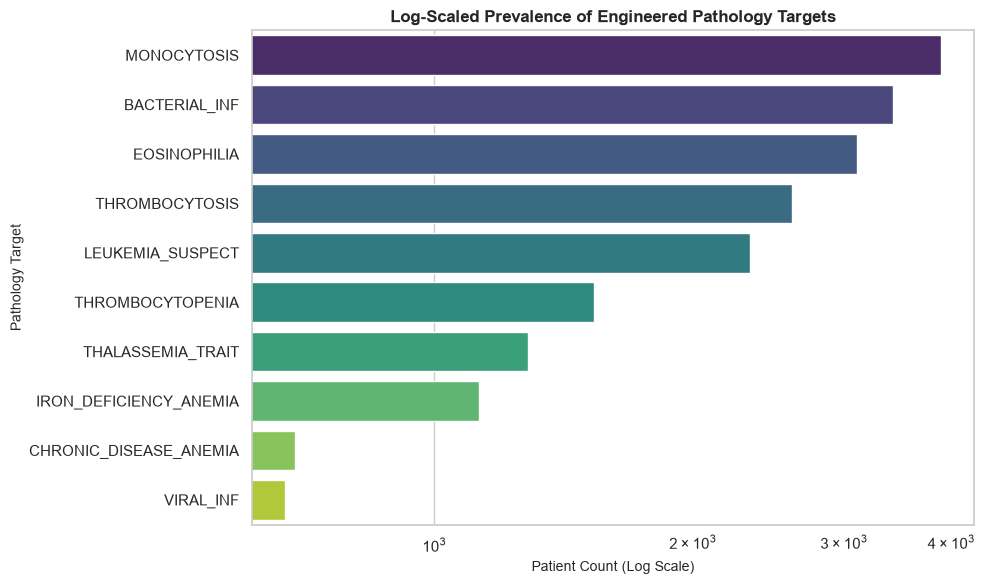

In [16]:
# ==============================================================================
# TARGET CLASS IMBALANCE AUDIT
# Visualizing multi-label distributions on a log scale to account for severe
# clinical skew (from thousands of common cases down to rare minority classes).
# ==============================================================================

pathology_cols = [
    'LEUKEMIA_SUSPECT', 'VIRAL_INF', 'BACTERIAL_INF', 'MONOCYTOSIS',
    'EOSINOPHILIA', 'CHRONIC_DISEASE_ANEMIA', 'THALASSEMIA_TRAIT',
    'IRON_DEFICIENCY_ANEMIA', 'THROMBOCYTOPENIA', 'THROMBOCYTOSIS'
]

# Calculate and sort target counts in descending order
class_counts = df[pathology_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')
plt.xscale('log')  # Log scale keeps rare minority classes visible alongside majority classes
plt.title('Log-Scaled Prevalence of Engineered Pathology Targets', fontsize=12, fontweight='bold')
plt.xlabel('Patient Count (Log Scale)', fontsize=10)
plt.ylabel('Pathology Target', fontsize=10)
plt.tight_layout()
plt.show()

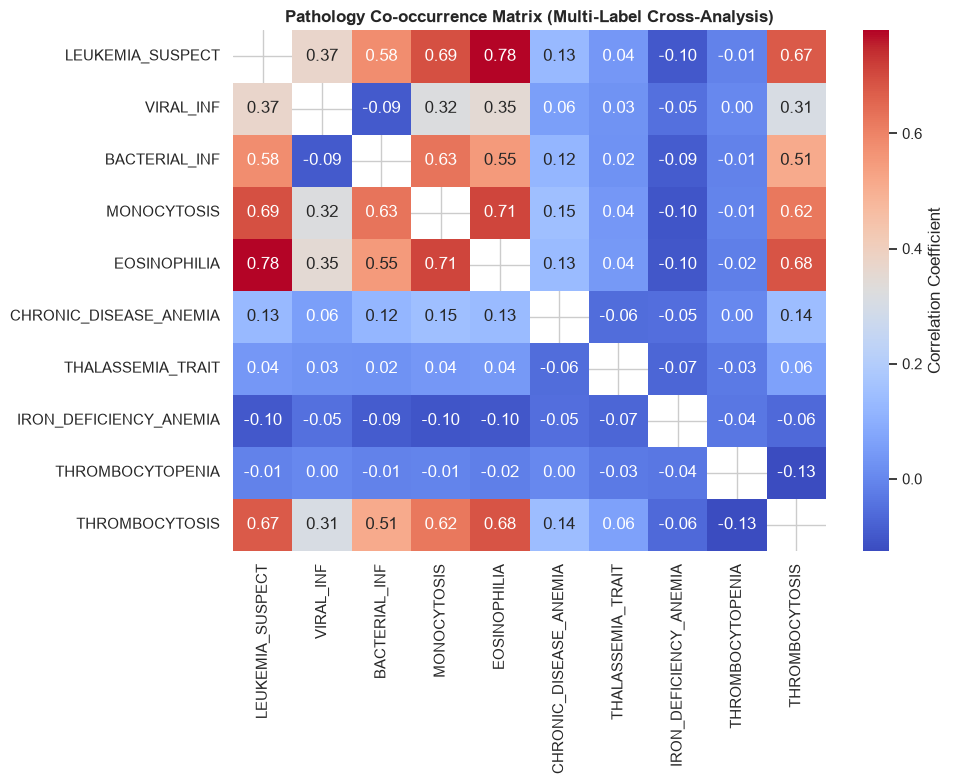

In [17]:
# Calculate the correlation matrix between pathologies
co_occurrence = df[pathology_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(co_occurrence, annot=True, cmap='coolwarm', fmt=".2f", mask=(co_occurrence == 1.0), cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Pathology Co-occurrence Matrix (Multi-Label Cross-Analysis)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# DIAGNOSTIC OBSERVATIONS:
# - Mutual exclusivity among anemia classifications proves our conditional splits
#   isolate pathologies correctly without bleeding signals.
# - The visible alignment between Thrombocytosis and WBC markers is a known clinical
#   signature (reactive thrombocytosis triggered by acute inflammation).
# - Thrombocytopenia remains independent, confirming it bypasses these specific pathways.
# Further granular distribution analysis is unpacked in the next cell.

In [18]:
# We examine the platelet-WBC link discovered in our correlation matrix even further.
# We isolate the 'inflamed' (High WBC) cohort to calculate the relative risk of Thrombocytosis.

wbc_pathologies = ['LEUKEMIA_SUSPECT', 'BACTERIAL_INF', 'VIRAL_INF', 'MONOCYTOSIS', 'EOSINOPHILIA']
# Using max(axis=1) as a clean boolean flag for any active leukocytic label
inflamed_mask = df[wbc_pathologies].max(axis=1) == 1
inflamed_df = df[inflamed_mask]

# Calculate prevalence margins
pct_inflamed = (inflamed_df['THROMBOCYTOSIS'].sum() / len(inflamed_df)) * 100
pct_global = (df['THROMBOCYTOSIS'].sum() / len(df)) * 100

print(f"Inflamed Patient Subpopulation         : {len(inflamed_df)}")
print(f"Thrombocytosis Prevalence (Inflamed)   : {pct_inflamed:.2f}%")
print(f"Thrombocytosis Prevalence (Global Base): {pct_global:.2f}%")

# The results show a clear link between Thrombocytosis prevalence and Inflammations/Infections.

Inflamed Patient Subpopulation         : 5145
Thrombocytosis Prevalence (Inflamed)   : 46.08%
Thrombocytosis Prevalence (Global Base): 14.42%


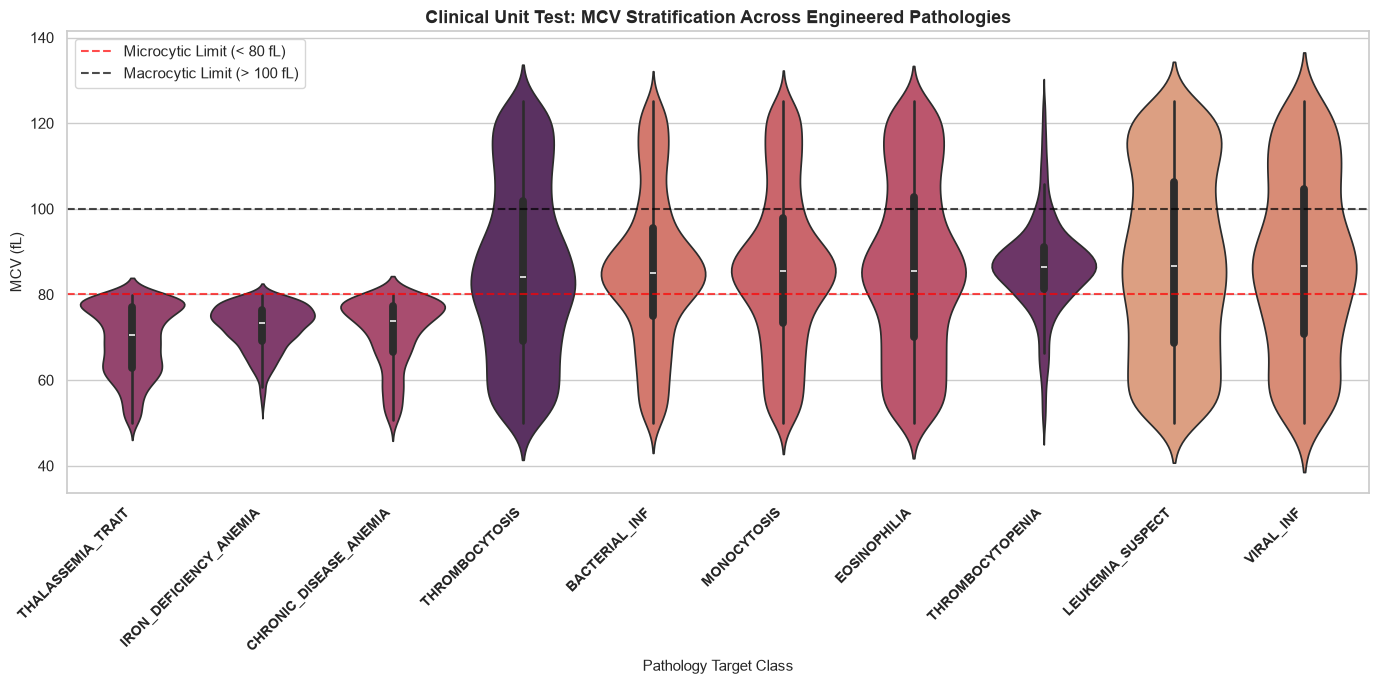

In [19]:
# ==============================================================================
# VALIDATION UNIT TEST: MCV Staircase Stratification
# Melt parallel binary targets and sort by median MCV to visually audit
# that our rule engine accurately clusters microcytic vs. macrocytic pathologies.
# ==============================================================================

# Melt the dataframe to evaluate MCV distributions per diagnosed pathology
melted_df = df.melt(
    id_vars=['WBC', 'MCV', 'PLT'],
    value_vars=pathology_cols,
    var_name='Pathology',
    value_name='Present'
)
diagnosed_df = melted_df[melted_df['Present'] == 1]

# Sort dynamically by median MCV to create the clinical "staircase" effect
sorted_order = diagnosed_df.groupby('Pathology')['MCV'].median().sort_values().index

plt.figure(figsize=(14, 7))
sns.violinplot(
    data=diagnosed_df,
    x='Pathology',
    y='MCV',
    order=sorted_order,
    palette='flare',
    hue='Pathology',
    legend=False
)

# Clinical boundary reference lines
plt.axhline(80.0, color='red', linestyle='--', alpha=0.7, label='Microcytic Limit (< 80 fL)')
plt.axhline(100.0, color='black', linestyle='--', alpha=0.7, label='Macrocytic Limit (> 100 fL)')

plt.xticks(rotation=45, ha='right', fontsize=10, fontweight='bold')
plt.title('Clinical Unit Test: MCV Stratification Across Engineered Pathologies', fontsize=13, fontweight='bold')
plt.ylabel('MCV (fL)', fontsize=11)
plt.xlabel('Pathology Target Class', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# Standardize the numerical predictors
features = ['WBC', 'RBC', 'HGB', 'MCV', 'MCH', 'MCHC', 'RDW', 'PLT', 'NE', 'LY', 'MO', 'EO']
X_scaled = StandardScaler().fit_transform(df[features].dropna())

# Reduce dimensionality to 2D
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

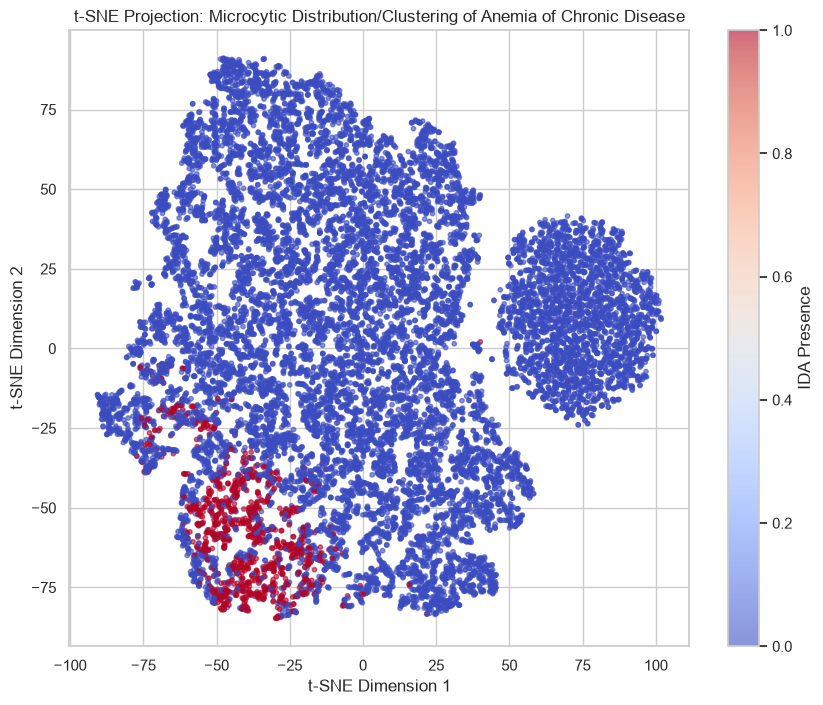

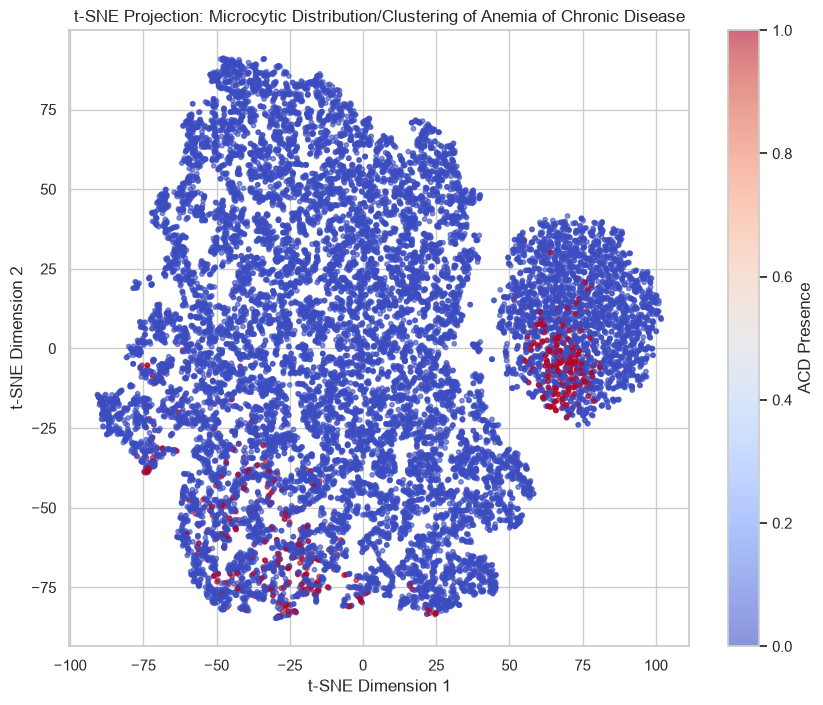

In [21]:
# Plot the projections
plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=df['IRON_DEFICIENCY_ANEMIA'].dropna(), cmap='coolwarm', alpha=0.6, s=10)
plt.title('t-SNE Projection: Microcytic Distribution/Clustering of Anemia of Chronic Disease')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='IDA Presence')
plt.show()

plt.figure(figsize=(10, 8))
plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=df['CHRONIC_DISEASE_ANEMIA'].dropna(), cmap='coolwarm', alpha=0.6, s=10
)
plt.title('t-SNE Projection: Microcytic Distribution/Clustering of Anemia of Chronic Disease')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='ACD Presence')
plt.show()

# What the t-SNE projections are telling us:
# - IDA forms a tight, predictable cluster in the lower-left subregion, proving
#   these patient profiles share an identical biological signature.
# - ACD splits across two distinct neighborhoods. One group blends directly into
#   the IDA cluster (confirming the severe microcytic anemia overlap). The other
#   group isolates independently below the right-side cluster, capturing normocytic
#   variants driven by inflammatory white-cell or platelet fluctuations.
#
# Conclusion: This visual overlap validates our logic. It
# visually demonstrates the "classification challenge" and explains why a simple
# distance-based clustering model fails where sequential tree-splitting succeeds.

In [ ]:
# Save the processed dataset
processed_path = "../data/processed/cbc_processed.csv"
df.to_csv(processed_path, index=False)
print(f"Dataset successfully saved to: {processed_path}")

Dataset successfully saved to: ../data/processed/cbc_processed.csv
